# Part 1 - Data Ingestion and Exploratory Data Analysis

**Capstone:** IBM AI Workflow - AI in Production

AAVAIL is a (hypothetical) streaming media company. The business opportunity is
to forecast revenue so that leadership can plan. This notebook covers the
Part 1 deliverables: restating the business opportunity, stating the data we
need, ingesting it, exploring it, and visualising what we learned.

All the data wrangling lives in `cslib.py` - this notebook only calls into it,
exactly as the assignment recommends.

## 1. The business opportunity and our hypotheses

**Business opportunity.** AAVAIL leadership needs to know how much revenue the
business will collect over the next 30 days, broken out by country, so they can
budget, staff and commit to content spend. Today that number is produced by a
spreadsheet that only looks backwards. We want a model that projects forward
from the transaction history.

Note the business metric and the model target are the *same* quantity here: the
next-30-day revenue total. That makes the model directly actionable.

**Testable hypotheses** (we check these against the data in this notebook):

| # | Hypothesis | How we test it |
|---|---|---|
| H1 | Revenue has short-term momentum, so recent revenue predicts the next 30 days. | Correlation of `previous_7/14/28/70` with the target |
| H2 | The same 30-day window one year earlier is predictive, implying yearly seasonality. | `previous_year` vs target correlation |
| H3 | A few countries dominate revenue, so a handful of country models (plus an overall model) covers the business. | Revenue share by country |
| H4 | Revenue is **not** stationary - level and trend shift over time, so predictions must be compared against recent actuals, not a single global average. | Time-series plot |
| H5 | Engagement measures (views, invoice counts) add signal beyond raw revenue. | Correlation of `recent_invoices` / `recent_views` with target |

## 2. Load the raw data

First we look at the raw invoice files. `fetch_data` is the ingestion function
required by the assignment - it validates its input, normalises the inconsistent
column names and returns a feature matrix.

In [1]:
import os
import sys

# Make sure the project root is importable when the notebook is run from
# the notebooks/ folder.
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)
os.chdir(PROJECT_ROOT)

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

from cslib import fetch_data, fetch_ts, engineer_features, FEATURE_NAMES

pd.options.display.max_columns = 20
pd.options.display.width = 160

# Figure sizes are set once so every plot in the notebook looks consistent.
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

DATA_DIR = os.path.join("data", "cs-train")
print("Project root :", PROJECT_ROOT)
print("Data dir     :", DATA_DIR)

Project root : D:\ibm  project
Data dir     : data\cs-train


### 2.1 What the raw files actually look like

The assignment warns that the monthly files do **not** share column names. Let's
confirm that on the real files before trusting the ingestion code.

In [2]:
import glob
import json

files = sorted(glob.glob(os.path.join(DATA_DIR, "*.json")))
print("{} monthly files found\n".format(len(files)))

print("{:<24} {}".format("file", "columns"))
print("-" * 100)
for f in files:
    with open(f) as fh:
        first = json.loads(fh.readline().strip().rstrip(","))
    if isinstance(first, list):
        first = first[0]
    print("{:<24} {}".format(os.path.basename(f), sorted(first.keys())))

print(
    "\n=> Confirmed: some months use 'StreamID'/'TimesViewed' and some use "
    "'total_price' instead of 'price'.\n   cslib.fetch_data() renames all of these "
    "to the canonical names before anything else happens."
)

21 monthly files found

file                     columns
----------------------------------------------------------------------------------------------------
invoices-2017-11.json    ['country', 'customer_id', 'day', 'invoice', 'month', 'price', 'stream_id', 'times_viewed', 'year']
invoices-2017-12.json    ['country', 'customer_id', 'day', 'invoice', 'month', 'stream_id', 'times_viewed', 'total_price', 'year']


invoices-2018-01.json    ['StreamID', 'TimesViewed', 'country', 'customer_id', 'day', 'invoice', 'month', 'total_price', 'year']
invoices-2018-02.json    ['StreamID', 'TimesViewed', 'country', 'customer_id', 'day', 'invoice', 'month', 'price', 'year']


invoices-2018-03.json    ['StreamID', 'TimesViewed', 'country', 'customer_id', 'day', 'invoice', 'month', 'price', 'year']
invoices-2018-04.json    ['StreamID', 'TimesViewed', 'country', 'customer_id', 'day', 'invoice', 'month', 'price', 'year']


invoices-2018-05.json    ['StreamID', 'TimesViewed', 'country', 'customer_id', 'day', 'invoice', 'month', 'price', 'year']
invoices-2018-06.json    ['StreamID', 'TimesViewed', 'country', 'customer_id', 'day', 'invoice', 'month', 'price', 'year']


invoices-2018-07.json    ['StreamID', 'TimesViewed', 'country', 'customer_id', 'day', 'invoice', 'month', 'price', 'year']
invoices-2018-08.json    ['StreamID', 'TimesViewed', 'country', 'customer_id', 'day', 'invoice', 'month', 'price', 'year']


invoices-2018-09.json    ['StreamID', 'TimesViewed', 'country', 'customer_id', 'day', 'invoice', 'month', 'price', 'year']
invoices-2018-10.json    ['StreamID', 'TimesViewed', 'country', 'customer_id', 'day', 'invoice', 'month', 'price', 'year']

invoices-2018-11.json    ['StreamID', 'TimesViewed', 'country', 'customer_id', 'day', 'invoice', 'month', 'price', 'year']
invoices-2018-12.json    ['StreamID', 'TimesViewed', 'country', 'customer_id', 'day', 'invoice', 'month', 'total_price', 'year']


invoices-2019-01.json    ['country', 'customer_id', 'day', 'invoice', 'month', 'stream_id', 'times_viewed', 'total_price', 'year']
invoices-2019-02.json    ['country', 'customer_id', 'day', 'invoice', 'month', 'price', 'stream_id', 'times_viewed', 'year']
invoices-2019-03.json    ['country', 'customer_id', 'day', 'invoice', 'month', 'price', 'stream_id', 'times_viewed', 'year']


invoices-2019-04.json    ['country', 'customer_id', 'day', 'invoice', 'month', 'price', 'stream_id', 'times_viewed', 'year']
invoices-2019-05.json    ['country', 'customer_id', 'day', 'invoice', 'month', 'price', 'stream_id', 'times_viewed', 'year']


invoices-2019-06.json    ['country', 'customer_id', 'day', 'invoice', 'month', 'price', 'stream_id', 'times_viewed', 'year']
invoices-2019-07.json    ['country', 'customer_id', 'day', 'invoice', 'month', 'price', 'stream_id', 'times_viewed', 'year']

=> Confirmed: some months use 'StreamID'/'TimesViewed' and some use 'total_price' instead of 'price'.
   cslib.fetch_data() renames all of these to the canonical names before anything else happens.


## 3. Ingest

Now run the ingestion function. It takes a couple of minutes the first time
because ~160MB of JSON has to be parsed; afterwards the result is cached as
small CSV files under `data/cs-train/ts-data/`.

In [3]:
import time

started = time.time()
raw = fetch_data(DATA_DIR)
print("fetch_data finished in {:.1f}s".format(time.time() - started))
print("\nshape :", raw.shape)
print("\ndtypes:\n", raw.dtypes)
raw.head()

fetch_data finished in 7.2s

shape : (815011, 11)

dtypes:
 country                    str
customer_id            float64
day                      int64
invoice                    str
month                    int64
price                  float64
stream_id                  str
times_viewed             int64
year                     int64
source_file                str
invoice_date    datetime64[us]
dtype: object


,country,customer_id,day,invoice,month,price,stream_id,times_viewed,year,source_file,invoice_date
0,United Kingdom,13085.0,28,489434,11,6.95,85048,12,2017,invoices-2017-11.json,2017-11-28
1,United Kingdom,NaN,28,489597,11,8.65,22130,1,2017,invoices-2017-11.json,2017-11-28
2,United Kingdom,NaN,28,489597,11,1.70,22132,6,2017,invoices-2017-11.json,2017-11-28
3,United Kingdom,NaN,28,489597,11,1.70,22133,4,2017,invoices-2017-11.json,2017-11-28
4,United Kingdom,NaN,28,489597,11,0.87,22134,1,2017,invoices-2017-11.json,2017-11-28


### 3.1 Did the ingestion actually clean things up?

Checks we care about:
* a real `invoice_date` datetime column exists
* no invoice id contains letters any more
* the nine canonical columns are all present

In [4]:
print("rows                       :", len(raw))
print("date range                 :", raw["invoice_date"].min().date(), "->", raw["invoice_date"].max().date())
print("invoice ids with letters   :", int(raw["invoice"].str.contains(r"[A-Za-z]").sum()))
print("duplicate invoice+date rows:", int(raw.duplicated(["invoice", "invoice_date"]).sum()))
print("null price rows            :", int(raw["price"].isna().sum()))
print("negative revenue rows      :", int((raw["price"] < 0).sum()))
print("\ncolumns:", sorted(raw.columns))

rows                       : 815011
date range                 : 2017-11-28 -> 2019-07-31


invoice ids with letters   : 0
duplicate invoice+date rows: 772365
null price rows            : 0
negative revenue rows      : 3

columns: ['country', 'customer_id', 'day', 'invoice', 'invoice_date', 'month', 'price', 'source_file', 'stream_id', 'times_viewed', 'year']


A couple of quick numbers about the business itself.

In [5]:
print("distinct countries :", raw["country"].nunique())
print("distinct customers :", int(raw["customer_id"].nunique()))
print("distinct invoices  :", int(raw["invoice"].nunique()))
print("distinct streams   :", int(raw["stream_id"].nunique()))
print("total revenue      : {:,.2f}".format(raw["price"].sum()))

distinct countries : 43
distinct customers : 5225
distinct invoices  : 42646


distinct streams   : 5007
total revenue      : 3,914,197.37


## 4. EDA - the story of the data

### 4.1 Hypothesis 3: is revenue concentrated in a few countries?

If a handful of countries carry the business, we only need a model for those.

In [6]:
by_country = (
    raw.groupby("country")
    .agg(revenue=("price", "sum"), invoices=("invoice", "nunique"), days=("invoice_date", "nunique"))
    .sort_values("revenue", ascending=False)
)
by_country["revenue_share_%"] = 100 * by_country["revenue"] / by_country["revenue"].sum()
print(by_country.to_string(float_format=lambda v: "{:,.2f}".format(v)))
print(
    "\n=> H3 supported: the top {} countries hold {:.1f}% of revenue.".format(
        5, by_country.head(5)["revenue_share_%"].sum()
    )
)

                          revenue  invoices  days  revenue_share_%
country                                                           
United Kingdom       3,521,513.50     39256   495            89.97
EIRE                   107,069.21       625   293             2.74
Germany                 49,271.82       812   359             1.26
France                  40,565.14       527   285             1.04
Norway                  38,494.75        29    19             0.98
Spain                   16,040.99       138   104             0.41
Hong Kong               14,452.57        12     9             0.37
Portugal                13,528.67        93    72             0.35
Singapore               13,175.92        11     6             0.34
Netherlands             12,322.80       199   133             0.31
Belgium                 11,190.61       133   109             0.29
Switzerland              9,284.05        91    73             0.24
Sweden                   7,876.76       107    67             

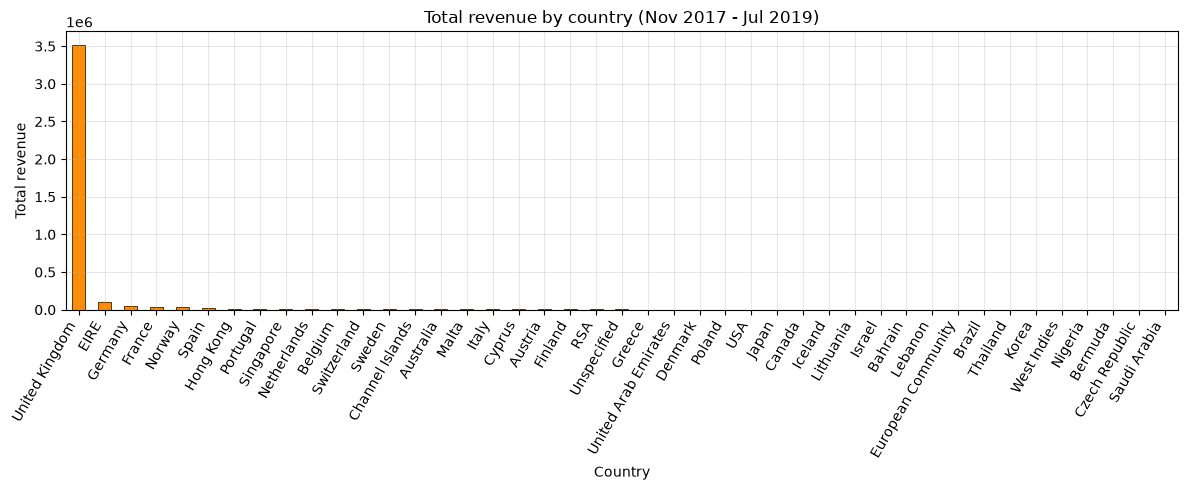

In [7]:
ax = by_country["revenue"].sort_values(ascending=False).plot(
    kind="bar", color="darkorange", edgecolor="black", linewidth=0.5
)
ax.set_title("Total revenue by country (Nov 2017 - Jul 2019)")
ax.set_xlabel("Country")
ax.set_ylabel("Total revenue")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

### 4.2 Hypothesis 4: is the revenue series stationary?

If revenue trends upward or has a seasonal swing, then a model trained on the
whole history will be stale by the time it is used. This is the single most
important plot in the notebook.

In [8]:
ts = fetch_ts(DATA_DIR)
daily = ts["all"]

print("daily time-series:", daily.shape[0], "days")
print("from", daily["date"].min().date(), "to", daily["date"].max().date())
daily.head()

... loading cached time-series data from 'data\cs-train\ts-data'
daily time-series: 611 days
from 2017-11-28 to 2019-07-31


,date,purchases,unique_invoices,unique_streams,total_views,revenue,year_month
0,2017-11-28,3223.0,166.0,1345.0,15047.0,14450.54,2017-11
1,2017-11-29,3277.0,133.0,1397.0,14159.0,13411.96,2017-11
2,2017-11-30,3002.0,150.0,1335.0,15766.0,13290.25,2017-11
3,2017-12-01,2559.0,107.0,1256.0,12524.0,9687.28,2017-12
4,2017-12-02,402.0,32.0,287.0,3313.0,1443.26,2017-12


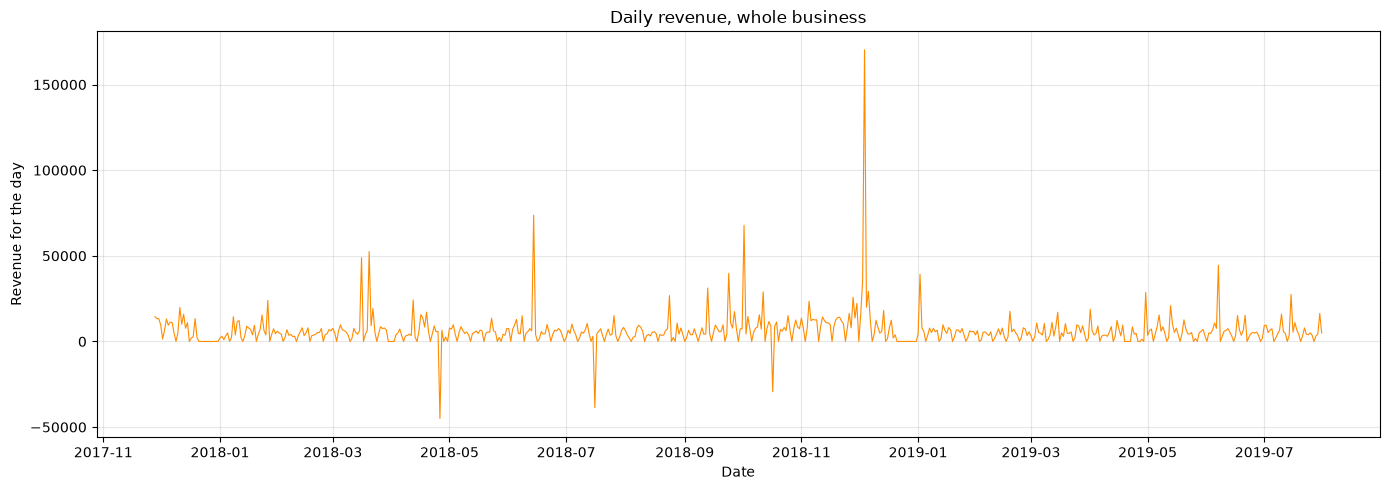

In [9]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(daily["date"], daily["revenue"], color="darkorange", linewidth=0.8)
ax.set_title("Daily revenue, whole business")
ax.set_xlabel("Date")
ax.set_ylabel("Revenue for the day")
plt.tight_layout()
plt.show()

The same thing as a 30-day rolling mean, which makes the trend obvious.

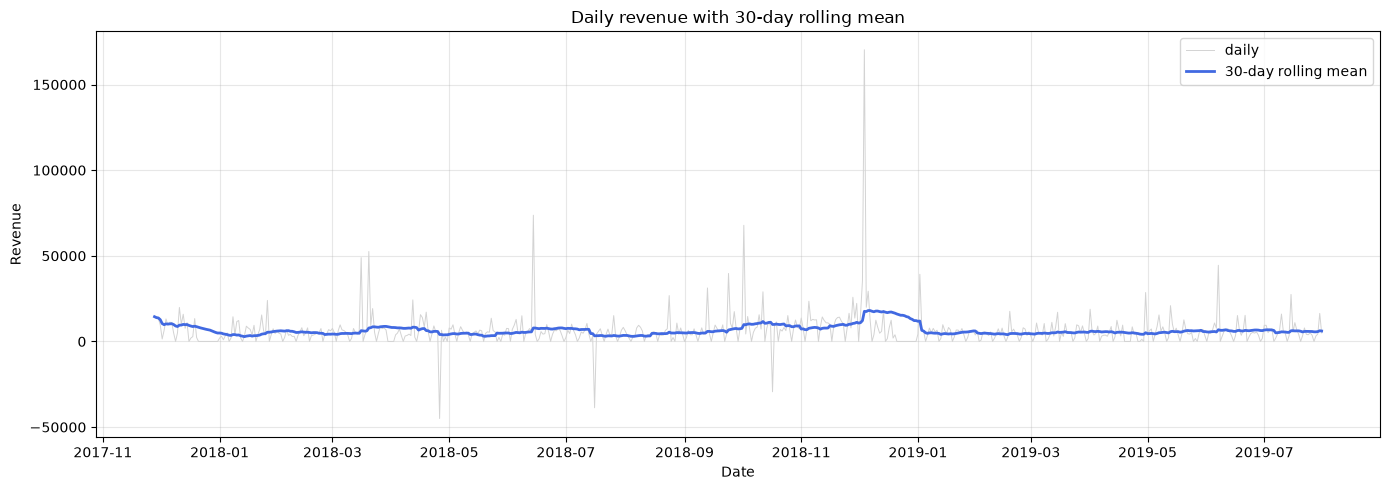

=> H4 supported: the level of revenue clearly rises and falls over the
   two year window, so the model must be evaluated against recent data and
   the API must support re-training as new months arrive.


In [10]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(daily["date"], daily["revenue"], color="lightgrey", linewidth=0.7, label="daily")
ax.plot(
    daily["date"],
    daily["revenue"].rolling(30, min_periods=1).mean(),
    color="royalblue",
    linewidth=2,
    label="30-day rolling mean",
)
ax.set_title("Daily revenue with 30-day rolling mean")
ax.set_xlabel("Date")
ax.set_ylabel("Revenue")
ax.legend()
plt.tight_layout()
plt.show()

print(
    "=> H4 supported: the level of revenue clearly rises and falls over the\n"
    "   two year window, so the model must be evaluated against recent data and\n"
    "   the API must support re-training as new months arrive."
)

### 4.3 Seasonality

If there is a yearly pattern we should see it in the monthly totals.

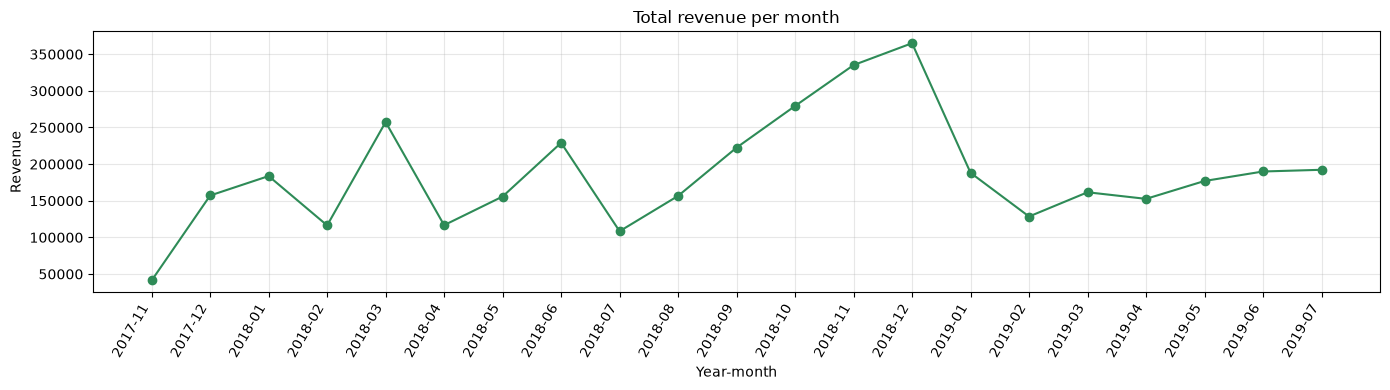

year_month
2017-11    41,153
2017-12   157,155
2018-01   183,680
2018-02   116,345
2018-03   257,428
2018-04   116,642
2018-05   155,749
2018-06   229,099
2018-07   108,379
2018-08   156,605
2018-09   222,501
2018-10   279,361
2018-11   335,171
2018-12   365,052
2019-01   188,111
2019-02   128,477
2019-03   161,573
2019-04   152,566
2019-05   176,966
2019-06   189,927
2019-07   192,256


In [11]:
monthly = daily.groupby("year_month")["revenue"].sum()
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(monthly.index, monthly.values, marker="o", color="seagreen")
ax.set_title("Total revenue per month")
ax.set_xlabel("Year-month")
ax.set_ylabel("Revenue")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

print(monthly.to_string(float_format=lambda v: "{:,.0f}".format(v)))

The feature-vs-target relationship is the real test of H1 and H2, so build the
feature matrix now and look at it.

In [12]:
X, y, dates = engineer_features(daily, training=True)
print("feature matrix :", X.shape)
print("target         :", y.shape)
print("date range     :", pd.Timestamp(dates[0]).date(), "->", pd.Timestamp(dates[-1]).date())
print("target mean    : {:,.0f}".format(y.mean()))
print("target std     : {:,.0f}".format(y.std()))

feature matrix : (551, 7)
target         : (551,)
date range     : 2017-11-29 -> 2019-06-02
target mean    : 191,486
target std     : 88,365


### 4.4 Hypotheses 1, 2 and 5: which features actually predict the target?

In [13]:
feat_df = pd.DataFrame(X, columns=FEATURE_NAMES)
feat_df["target_next_30_days"] = y
feat_df["date"] = pd.to_datetime(dates)

corr = feat_df[FEATURE_NAMES + ["target_next_30_days"]].corr()["target_next_30_days"].drop("target_next_30_days")
corr = corr.sort_values(ascending=False)

print("Correlation of each feature with the 30-day revenue target")
print("-" * 52)
for name, value in corr.items():
    print("{:<20} {:>8.3f}".format(name, value))

Correlation of each feature with the 30-day revenue target
----------------------------------------------------
recent_invoices         0.431
recent_views            0.392
previous_70             0.183
previous_7              0.174
previous_14             0.154
previous_28             0.152
previous_year           0.112


The result is **not** what the course's reference implementation assumes. The
reference keeps only the revenue windows, but on this data the two engagement
features are the strongest single predictors, and every correlation is modest
(0.11 - 0.43). So Part 2 treats "which features to use" as one of the
iterations to test rather than a fixed choice, and measures it with RMSE.

In [14]:
print(
    "=> H1 weakly supported: every revenue window correlates positively with the\n"
    "   target, but only weakly (0.15 - 0.18). The longer the window, the better\n"
    "   it does, which makes sense - the target is a 30 day total.\n"
    "=> H2 NOT supported: `previous_year` is the weakest feature (0.11). The\n"
    "   training set is only 21 months, so a year-earlier window is mostly empty.\n"
    "=> H5 SUPPORTED: `recent_invoices` (0.43) and `recent_views` (0.39) beat every\n"
    "   revenue window. Engagement carries signal that pure revenue lags miss."
)

=> H1 weakly supported: every revenue window correlates positively with the
   target, but only weakly (0.15 - 0.18). The longer the window, the better
   it does, which makes sense - the target is a 30 day total.
=> H2 NOT supported: `previous_year` is the weakest feature (0.11). The
   training set is only 21 months, so a year-earlier window is mostly empty.
=> H5 SUPPORTED: `recent_invoices` (0.43) and `recent_views` (0.39) beat every
   revenue window. Engagement carries signal that pure revenue lags miss.


### 4.5 Relationship plots

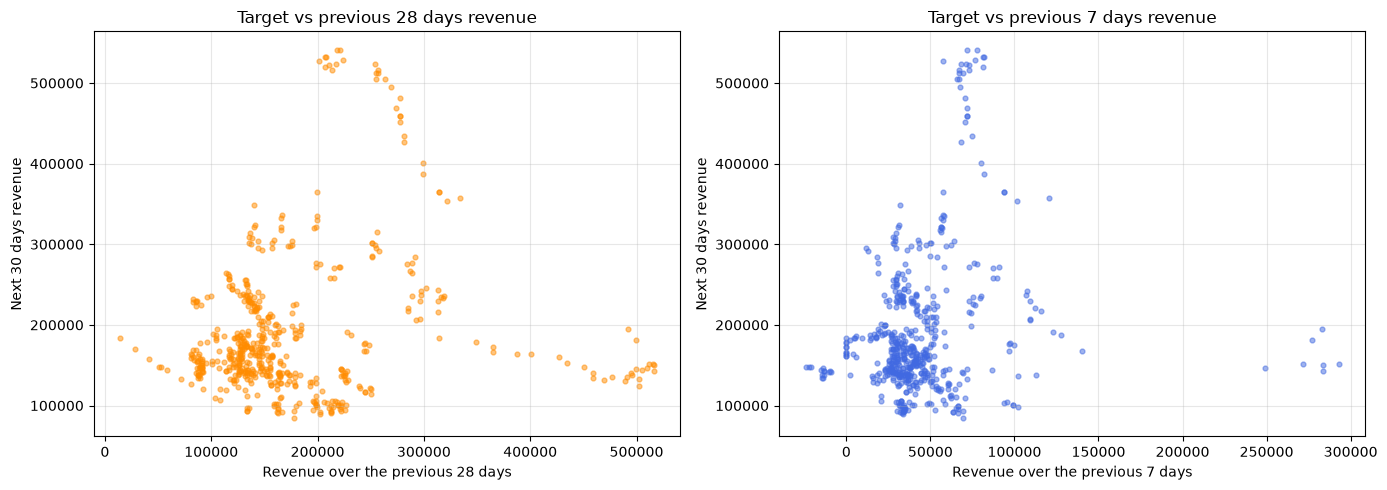

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(feat_df["previous_28"], feat_df["target_next_30_days"], s=12, alpha=0.5, color="darkorange")
axes[0].set_title("Target vs previous 28 days revenue")
axes[0].set_xlabel("Revenue over the previous 28 days")
axes[0].set_ylabel("Next 30 days revenue")
axes[1].scatter(feat_df["previous_7"], feat_df["target_next_30_days"], s=12, alpha=0.5, color="royalblue")
axes[1].set_title("Target vs previous 7 days revenue")
axes[1].set_xlabel("Revenue over the previous 7 days")
axes[1].set_ylabel("Next 30 days revenue")
plt.tight_layout()
plt.show()

Does the relationship look linear? Plot the two heaviest countries separately,
because 'all' is dominated by the United Kingdom and would hide the structure.

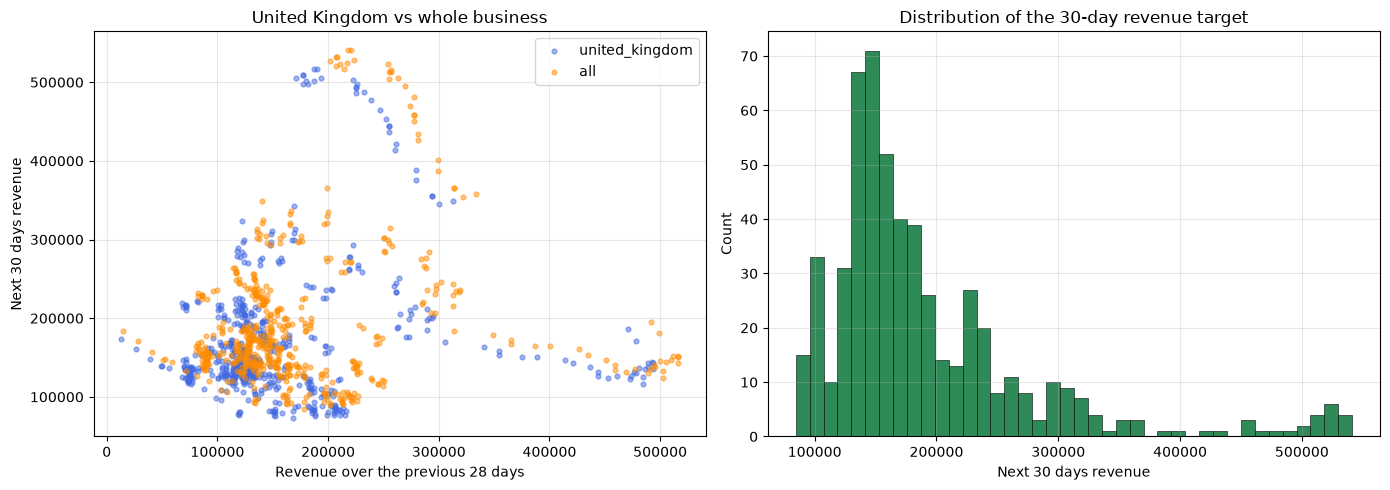

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for key, color in (("united_kingdom", "royalblue"), ("all", "darkorange")):
    Xk, yk, _ = engineer_features(ts[key], training=True)
    axes[0].scatter(Xk[:, FEATURE_NAMES.index("previous_28")], yk, s=12, alpha=0.5, label=key, color=color)
axes[0].set_title("United Kingdom vs whole business")
axes[0].set_xlabel("Revenue over the previous 28 days")
axes[0].set_ylabel("Next 30 days revenue")
axes[0].legend()
axes[1].hist(feat_df["target_next_30_days"], bins=40, color="seagreen", edgecolor="black", linewidth=0.4)
axes[1].set_title("Distribution of the 30-day revenue target")
axes[1].set_xlabel("Next 30 days revenue")
axes[1].set_ylabel("Count")
plt.tight_layout()
plt.show()

### 4.6 How much data will a model actually get?

Some countries are small, so the feature matrix shrinks. Worth knowing before
choosing a model.

In [17]:
rows = []
for key, frame in ts.items():
    Xk, yk, dk = engineer_features(frame, training=True)
    rows.append(
        {
            "country": key,
            "daily_rows": len(frame),
            "train_rows": Xk.shape[0],
            "target_mean": yk.mean(),
            "target_std": yk.std(),
        }
    )
summary = pd.DataFrame(rows).sort_values("target_mean", ascending=False)
print(summary.to_string(index=False, float_format=lambda v: "{:,.1f}".format(v)))
print(
    "\n=> This is why the pipeline is careful: a small country can end up with a\n"
    "   few dozen training rows, which is not much for a tree ensemble."
)

       country  daily_rows  train_rows  target_mean  target_std
           all         611         551    191,486.0    88,365.0
united_kingdom         611         551    171,754.5    86,233.3
          eire         608         548      5,240.5     4,478.3
       germany         611         551      2,402.9       918.4
        france         611         551      2,038.5     1,132.1
     hong_kong         428         272      1,541.5     2,163.9
     singapore         448         250      1,477.2     3,998.6
         spain         603         543        809.9       984.8
      portugal         611         551        708.2     1,534.3
   netherlands         596         536        631.5       321.5
        norway         593         397        218.0       478.7

=> This is why the pipeline is careful: a small country can end up with a
   few dozen training rows, which is not much for a tree ensemble.


## 5. Findings

1. **The data is dirty in three documented ways** - inconsistent column names,
invoice ids containing letters, and a mix of per-transaction and per-month
files. All three are handled once, in `cslib.fetch_data`. After ingestion
there are 815,011 clean line items across 611 days (2017-11-28 to 2019-07-31)
with no invoice ids containing letters.
2. **Revenue is extremely concentrated.** The United Kingdom alone is ~90% of
revenue and the top five countries are ~96%. That is why the pipeline builds
models for the top 10 countries plus an `all` model, rather than one model
per country.
3. **Revenue is not stationary.** The 30-day rolling mean rises and falls
noticeably over the two years, which is the main reason the model must be
re-trained and monitored after deployment.
4. **Predictive power is limited and the best single feature is an engagement
count, not revenue.** Correlations top out at 0.43. Revenue history helps but
is weak, and the one-year-earlier window is nearly useless in a 21 month
training set.
5. **The number of usable training rows is modest** (551 at best, 250 for the
smallest modelled country), so simple, well-regularised models are the right
choice. That is what Part 2 compares.

### Next step

Part 2 compares several regression models against this feature matrix and picks
one using RMSE. See `notebooks/02_model_comparison_part2.ipynb`.